# **Step 6 – Selección de algoritmos (preliminar)**
**Proyecto TA – Análisis de Datos (1INF03, 2026-2) – Equipo E10**

> *KDD, paso 6:* «Choosing the data mining algorithms: which models and parameters may be appropriate for searching for patterns (e.g. models for categorical data or models on vectors over the reals).»

Los pasos 5 y 6 son opcionales en el avance. Este notebook justifica **qué modelos proponemos** y da una **primera evidencia** de que hay señal en los datos.

**Tarea:** clasificación binaria (Step 5). Etiqueta principal `alteracion_estricta`; sensibilidad `alteracion`.
**Modelos candidatos (vistos en clase):** regresión logística, KNN y SVC, frente a una línea base que siempre predice la clase mayoritaria.

**Reglas para no engañarse**
- Solo se usa **entrenamiento** (90 niños); la prueba (31 niños) **no se toca**.
- Validación cruzada **agrupada por niño** (`StratifiedGroupKFold`, 5 pliegues × 10 repeticiones): todas las evaluaciones de un niño quedan juntas.
- Residuos por edad y escalado van **dentro de un `Pipeline`**, así se ajustan solo con el pliegue de entrenamiento (sin fuga).
- Se reporta AUC-ROC, exactitud balanceada y F1 macro, no solo la exactitud.
- Hiperparámetros **fijos** en esta etapa; el ajuste fino se hará en la entrega final.

## Librerías, datos y transformadores
`ResiduosEdad` es el mismo transformador del Step 4 (se copia para que el notebook sea autocontenido). `Seleccionar` elige el conjunto de variables y `Escalar` estandariza todo menos `sexo_m`.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import json
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.model_selection import StratifiedGroupKFold, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.dummy import DummyClassifier
from sklearn.cluster import KMeans
from sklearn.metrics import roc_auc_score, balanced_accuracy_score, f1_score, accuracy_score, adjusted_rand_score, normalized_mutual_info_score
LIM, TRA = Path("../datos/2_limpios"), Path("../datos/3_transformados")
RES, FIG = Path("../datos/4_resultados"), Path("../figuras")
sns.set_theme(style="whitegrid"); plt.rcParams["figure.dpi"] = 110

class ResiduosEdad(BaseEstimator, TransformerMixin):
    """Agrega res_peso, res_talla, res_imc = valor - esperado(edad, sexo), con un polinomio de grado 3 por sexo."""
    MED = {"Peso_kg": "res_peso", "Talla_cm": "res_talla", "IMC_valor": "res_imc"}
    def fit(self, X, y=None):
        self.curvas_ = {(c, s): LinearRegression().fit(self._f(X[X["sexo_m"] == s]), X.loc[X["sexo_m"] == s, c])
                        for c in self.MED for s in (0, 1)}
        return self
    def transform(self, X):
        X = X.copy()
        for c, nom in self.MED.items():
            X[nom] = np.nan
            for s in (0, 1):
                m = X["sexo_m"] == s
                if m.any(): X.loc[m, nom] = X.loc[m, c] - self.curvas_[(c, s)].predict(self._f(X[m]))
        return X
    @staticmethod
    def _f(d): e = d["edad_ev"].to_numpy(); return np.c_[e, e**2, e**3]

class Seleccionar(BaseEstimator, TransformerMixin):
    def __init__(self, cols): self.cols = cols
    def fit(self, X, y=None): return self
    def transform(self, X): return X[self.cols]

class Escalar(BaseEstimator, TransformerMixin):
    """StandardScaler sobre todas las columnas salvo sexo_m (que queda 0/1)."""
    def fit(self, X, y=None):
        self.num_ = [c for c in X.columns if c != "sexo_m"]; self.sc_ = StandardScaler().fit(X[self.num_]); return self
    def transform(self, X):
        X = X.copy(); X[self.num_] = self.sc_.transform(X[self.num_]); return X

def pipe(modelo, cols): return Pipeline([("residuos", ResiduosEdad()), ("seleccionar", Seleccionar(cols)), ("escalar", Escalar()), ("modelo", modelo)])

VARS = ["edad_ev","sexo_m","Peso_kg","Talla_cm","IMC_valor"]
CRUDAS, AJUST = VARS, ["res_peso","res_talla","res_imc"]
conjuntos = {"crudas": CRUDAS, "crudas + ajustadas": CRUDAS + AJUST, "solo ajustadas": AJUST}
targets = ["alteracion_estricta", "alteracion"]
tr = pd.read_csv(TRA/"step4_train.csv", sep="|"); g = tr["id_nna"]; X = tr[VARS]
print("Evaluaciones:", len(tr), "| niños:", g.nunique())
for t in targets: print(f"{t}: {100*tr[t].mean():.1f} % positivos")

Evaluaciones: 236 | niños: 90
alteracion_estricta: 37.3 % positivos
alteracion: 67.4 % positivos


## 1. Comparación de modelos y de conjuntos de variables
`evaluar` repite 10 veces una validación cruzada agrupada por niño de 5 pliegues. En cada repetición junta las predicciones de los 5 pliegues de validación y calcula las métricas; luego promedia las repeticiones.

In [2]:
modelos = {"Línea base": DummyClassifier(strategy="most_frequent"),
           "Regresión logística": LogisticRegression(class_weight="balanced", C=0.5, max_iter=2000),
           "KNN (k=9)": KNeighborsClassifier(n_neighbors=9),
           "SVC (rbf)": SVC(kernel="rbf", C=1, class_weight="balanced")}
def puntaje(m, Xv):
    if hasattr(m, "decision_function"): return m.decision_function(Xv)
    return m.predict_proba(Xv)[:, 1]
def evaluar(modelo, cols, y, X=X, grupos=g, reps=10):
    met = {"AUC": [], "bal": [], "F1": [], "acc": []}
    for r in range(reps):
        cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=r)
        pred, score = np.zeros(len(y)), np.zeros(len(y))
        for i, j in cv.split(X, y, grupos):
            m = pipe(clone(modelo), cols).fit(X.iloc[i], y.iloc[i])
            pred[j] = m.predict(X.iloc[j]); score[j] = puntaje(m, X.iloc[j])
        met["AUC"].append(roc_auc_score(y, score) if len(set(score)) > 1 else 0.5)
        met["bal"].append(balanced_accuracy_score(y, pred)); met["F1"].append(f1_score(y, pred, average="macro")); met["acc"].append(accuracy_score(y, pred))
    return {k: (np.mean(v), np.std(v)) for k, v in met.items()}
filas = []
for t in targets:
    for cn, cols in conjuntos.items():
        for mn, md in modelos.items():
            if mn == "Línea base" and cn != "crudas": continue
            r = evaluar(md, cols, tr[t])
            filas.append({"etiqueta": t, "variables": cn, "modelo": mn, "AUC": r["AUC"][0], "AUC (desv. entre repeticiones)": r["AUC"][1],
                          "exactitud balanceada": r["bal"][0], "F1 macro": r["F1"][0], "exactitud": r["acc"][0]})
res = pd.DataFrame(filas); res.to_csv(RES/"step6_comparacion.csv", sep="|", index=False); res.round(3)

,etiqueta,variables,modelo,AUC,AUC (desv. entre repeticiones),exactitud balanceada,F1 macro,exactitud
0,alteracion_estricta,crudas,Línea base,0.500,0.000,0.500,0.385,0.627
1,alteracion_estricta,crudas,Regresión logística,0.747,0.025,0.672,0.669,0.686
2,alteracion_estricta,crudas,KNN (k=9),0.676,0.040,0.611,0.612,0.658
3,alteracion_estricta,crudas,SVC (rbf),0.773,0.033,0.679,0.676,0.694
4,alteracion_estricta,crudas + ajustadas,Regresión logística,0.852,0.016,0.763,0.761,0.776
5,alteracion_estricta,crudas + ajustadas,KNN (k=9),0.737,0.024,0.688,0.694,0.730
6,alteracion_estricta,crudas + ajustadas,SVC (rbf),0.829,0.019,0.747,0.741,0.752
7,alteracion_estricta,solo ajustadas,Regresión logística,0.831,0.015,0.743,0.741,0.756
8,alteracion_estricta,solo ajustadas,KNN (k=9),0.754,0.015,0.699,0.703,0.730
9,alteracion_estricta,solo ajustadas,SVC (rbf),0.819,0.018,0.756,0.746,0.755


Se grafica el AUC por modelo y conjunto de variables, para cada etiqueta.

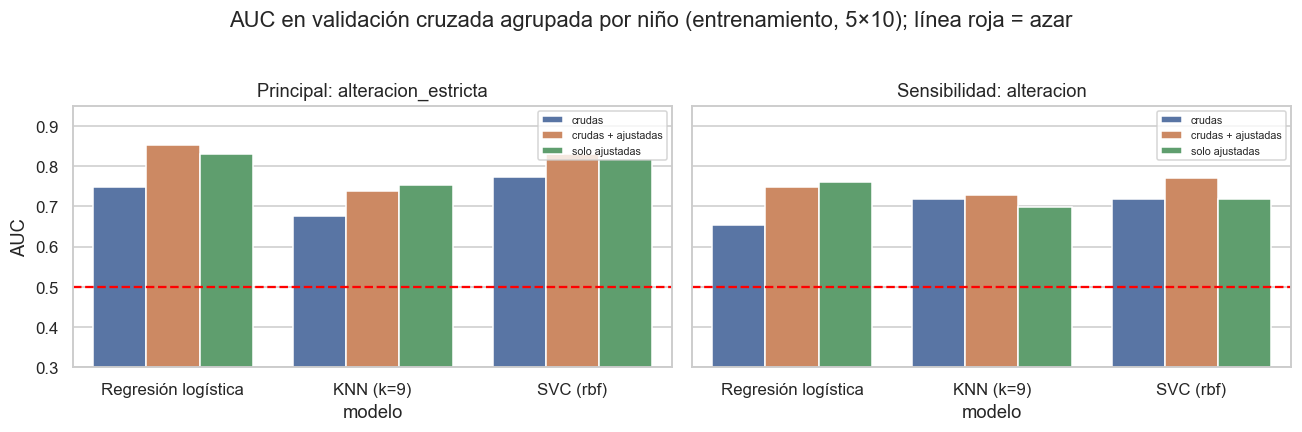

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(12,3.8), sharey=True)
for a, t in zip(ax, targets):
    d = res[(res["etiqueta"]==t) & (res["modelo"]!="Línea base")]
    sns.barplot(data=d, x="modelo", y="AUC", hue="variables", ax=a, palette=["#4C72B0","#DD8452","#55A868"])
    a.axhline(0.5, color="red", ls="--"); a.set_ylim(0.3, 0.95); a.set_title(("Principal: " if t=="alteracion_estricta" else "Sensibilidad: ")+t); a.legend(fontsize=7, loc="upper right")
plt.suptitle("AUC en validación cruzada agrupada por niño (entrenamiento, 5×10); línea roja = azar", y=1.03)
plt.tight_layout(); plt.savefig(FIG/"step6_auc_modelos.png", bbox_inches="tight"); plt.show()

**Interpretación.**
1. **Con la etiqueta principal hay señal real.** La mejor combinación es la **regresión logística con variables crudas + ajustadas (AUC 0,852)**, seguida del SVC con las mismas variables (0,829), frente a 0,5 de la línea base. Con la etiqueta amplia (incluye *riesgos*) la señal es **moderada** (AUC 0,65 a 0,77): los riesgos son un diagnóstico más ambiguo y se explican peor con las medidas.
2. **Las variables ajustadas por edad ayudan.** Con la logística el AUC sube de 0,747 (solo crudas) a 0,852 (crudas + ajustadas): lo informativo es la **desviación respecto a lo esperado para la edad** (Step 4).
3. **KNN queda por debajo** (0,68 a 0,75 con la etiqueta principal): con variables correlacionadas y pocos datos, las distancias se diluyen.
4. **Cuidado al comparar:** la desviación entre repeticiones (0,02 a 0,04) solo refleja cómo se arman los pliegues, **no** la incertidumbre por tener 90 niños, que es mayor (§5). Diferencias de ≈0,02 entre logística y SVC no son concluyentes por sí solas.

## 2. ¿El resultado se distingue del azar? Prueba de permutaciones por niño
Se **barajan las etiquetas entre niños** (se intercambia el vector de etiquetas de un niño con el de otro que tiene el mismo número de evaluaciones) y se repite la validación. Así se conserva la estructura por niño. Se usa la regresión logística con variables crudas + ajustadas y la etiqueta principal; el AUC real y los barajados se calculan con **el mismo número de repeticiones** (2).

AUC real = 0.837 | barajados: media 0.552, percentil 95 = 0.668 | p-valor = 0.010


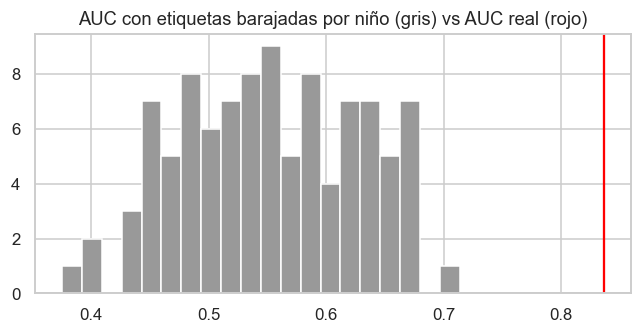

In [4]:
rng = np.random.default_rng(1)
cols_p, y = conjuntos["crudas + ajustadas"], tr["alteracion_estricta"]
auc_cv = lambda yv: evaluar(modelos["Regresión logística"], cols_p, yv, reps=2)["AUC"][0]
real = auc_cv(y)
por_nino = {k: v.values for k, v in y.groupby(g)}
tam = pd.Series({k: len(v) for k, v in por_nino.items()})
nulos = []
for _ in range(100):
    yp = y.copy()
    for n, ids in tam.groupby(tam).groups.items():
        ids = list(ids); perm = rng.permutation(len(ids))
        for k, p in zip(ids, perm): yp[g == k] = por_nino[ids[p]]
    nulos.append(auc_cv(yp))
nulos = np.array(nulos); p_perm = (1 + (nulos >= real).sum()) / (1 + len(nulos)); p95 = np.percentile(nulos, 95)
print(f"AUC real = {real:.3f} | barajados: media {nulos.mean():.3f}, percentil 95 = {p95:.3f} | p-valor = {p_perm:.3f}")
plt.figure(figsize=(6,3.2)); plt.hist(nulos, bins=20, color="#999"); plt.axvline(real, color="red")
plt.title("AUC con etiquetas barajadas por niño (gris) vs AUC real (rojo)"); plt.tight_layout(); plt.savefig(FIG/"step6_permutaciones.png", bbox_inches="tight"); plt.show()

**Interpretación.** El AUC real (**0,837**) queda muy por encima de lo que se obtiene con etiquetas barajadas por niño (media 0,552; percentil 95 = 0,668), con *p* = 0,010, el mínimo posible con 100 permutaciones. **La señal no es casualidad**, a diferencia del análisis solo con la ficha (Anexo Step 6), donde el AUC no se distinguía del azar. Como la permutación conserva la estructura por niño, el resultado no está inflado por repetir niños. (El AUC real difiere levemente del de §1 porque aquí se usan 2 repeticiones en lugar de 10, igual que en las permutaciones.)

## 3. ¿Cuánto aporta cada variable? Ablación con regresión logística
Se repite el modelo quitando variables, para saber de dónde viene la señal (5 repeticiones).

In [5]:
blq = {"todas (crudas + ajustadas)": CRUDAS + AJUST, "sin edad ni sexo": ["Peso_kg","Talla_cm","IMC_valor"] + AJUST,
       "solo edad": ["edad_ev"], "solo edad y sexo": ["edad_ev","sexo_m"], "solo IMC": ["IMC_valor"],
       "solo residuo de IMC": ["res_imc"], "solo residuos (peso, talla, IMC)": AJUST}
f = []
for t in targets:
    for b, cl in blq.items():
        r = evaluar(modelos["Regresión logística"], cl, tr[t], reps=5)
        f.append({"etiqueta": t, "variables": b, "AUC": round(r["AUC"][0],3), "exactitud balanceada": round(r["bal"][0],3)})
abl = pd.DataFrame(f); abl.to_csv(RES/"step6_ablacion.csv", sep="|", index=False); abl

,etiqueta,variables,AUC,exactitud balanceada
0,alteracion_estricta,todas (crudas + ajustadas),0.853,0.766
1,alteracion_estricta,sin edad ni sexo,0.830,0.751
2,alteracion_estricta,solo edad,0.489,0.493
3,alteracion_estricta,solo edad y sexo,0.558,0.568
4,alteracion_estricta,solo IMC,0.712,0.662
5,alteracion_estricta,solo residuo de IMC,0.802,0.736
6,alteracion_estricta,"solo residuos (peso, talla, IMC)",0.839,0.753
7,alteracion,todas (crudas + ajustadas),0.756,0.676
8,alteracion,sin edad ni sexo,0.762,0.696
9,alteracion,solo edad,0.566,0.586


**Interpretación.**
- **La edad por sí sola no sirve** (AUC 0,49 con la etiqueta principal): la alteración se da a todas las edades.
- **La señal viene de la desviación respecto a lo esperado para la edad:** el residuo de IMC solo da 0,80 y los tres residuos juntos 0,84, muy por encima del IMC crudo (0,71).
- Quitar edad y sexo casi no cambia el resultado (0,83 frente a 0,85): una vez ajustadas las medidas, la edad aporta poco.
- Con la etiqueta amplia, "solo residuos" (0,77) rinde igual que todas las variables (0,76): con tan pocos datos, un conjunto más simple no pierde. Es una opción a considerar en la versión final.

## 4. Exploración del clustering (enfoque no supervisado, línea futura)
Se prueba si los **grupos que forma K-Means** con las medidas coinciden con la etiqueta. En cada pliegue, residuos, escalado y K-Means se ajustan con el entrenamiento; a cada niño de validación se le asigna el grupo más cercano y su "predicción" es la proporción de alteración de ese grupo. Además se mide la coincidencia directa entre grupos y etiqueta con ARI y NMI (0 = ninguna).

In [6]:
def transformar(cols, Xa, Xb=None):
    p = Pipeline([("residuos", ResiduosEdad()), ("seleccionar", Seleccionar(cols)), ("escalar", Escalar())]).fit(Xa)
    return p.transform(Xa), (p.transform(Xb) if Xb is not None else None)
def evaluar_km(cols, y, k, reps=5):
    aucs = []
    for r in range(reps):
        cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=r); s = np.zeros(len(y))
        for i, j in cv.split(X, y, g):
            Zi, Zj = transformar(cols, X.iloc[i], X.iloc[j])
            km = KMeans(n_clusters=k, n_init=10, random_state=r).fit(Zi)
            tasa = pd.Series(y.iloc[i].values).groupby(km.labels_).mean()
            s[j] = pd.Series(km.predict(Zj)).map(tasa).fillna(y.iloc[i].mean()).values
        aucs.append(roc_auc_score(y, s))
    return np.mean(aucs)
fk = []
for t in targets:
    y = tr[t]
    for cn in ["crudas", "solo ajustadas"]:
        Z, _ = transformar(conjuntos[cn], X)
        for k in [2,3,4,5,6]:
            lab = KMeans(n_clusters=k, n_init=10, random_state=0).fit_predict(Z)
            fk.append({"etiqueta": t, "variables": cn, "k": k, "AUC (grupos)": round(evaluar_km(conjuntos[cn], y, k),3),
                       "ARI": round(adjusted_rand_score(y, lab),3), "NMI": round(normalized_mutual_info_score(y, lab),3)})
fk = pd.DataFrame(fk); fk.to_csv(RES/"step6_kmeans.csv", sep="|", index=False); fk

,etiqueta,variables,k,AUC (grupos),ARI,NMI
0,alteracion_estricta,crudas,2,0.498,0.052,0.027
1,alteracion_estricta,crudas,3,0.483,0.026,0.022
2,alteracion_estricta,crudas,4,0.499,0.025,0.027
3,alteracion_estricta,crudas,5,0.480,0.026,0.029
4,alteracion_estricta,crudas,6,0.509,0.008,0.029
5,alteracion_estricta,solo ajustadas,2,0.596,0.182,0.122
6,alteracion_estricta,solo ajustadas,3,0.534,0.108,0.107
7,alteracion_estricta,solo ajustadas,4,0.657,0.070,0.082
8,alteracion_estricta,solo ajustadas,5,0.713,0.132,0.158
9,alteracion_estricta,solo ajustadas,6,0.757,0.128,0.122


**Interpretación.** Los grupos de K-Means con las **medidas crudas** no se relacionan con la etiqueta (AUC 0,48 a 0,51, ARI ≈ 0): se arman por tamaño y edad. Con las **medidas ajustadas** hay algo de relación (AUC hasta 0,76 con 6 grupos; ARI ≤ 0,18), pero queda **por debajo** de los modelos supervisados (0,85) y, con 6 grupos, el clustering ya funciona casi como un clasificador y pierde su valor descriptivo. **Conclusión:** el enfoque supervisado es el principal; el clustering (idealmente K-Prototypes o Gower, combinando medidas ajustadas y variables del hogar) queda como línea futura para describir perfiles.

## 5. Sensibilidad a la partición entrenamiento/prueba
Con pocos niños, **qué niños caen en entrenamiento** cambia los resultados. Para medirlo se repite la partición por niño (75/25, estratificada) con 20 semillas distintas y, en cada una, se calcula el AUC de validación cruzada agrupada **dentro del entrenamiento** (3 repeticiones), para la regresión logística y el SVC con crudas + ajustadas y la etiqueta principal. La prueba de cada partición tampoco se usa.

Semillas evaluadas: 20 (incluye 2026, la partición usada)
                      mean    std    min    max
modelo                                         
Regresión logística  0.822  0.030  0.755  0.861
SVC (rbf)            0.789  0.035  0.708  0.835


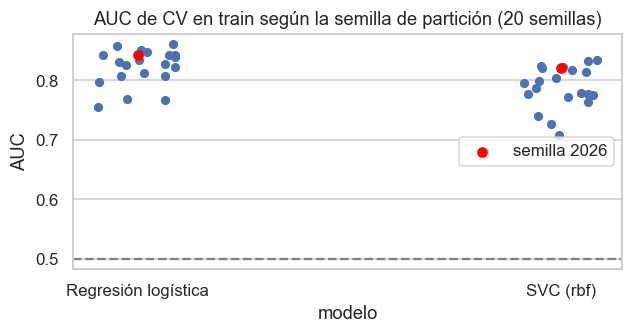

In [7]:
ev = pd.read_csv(LIM/"step3_evaluaciones.csv", sep="|")
nino = ev.groupby("id_nna")["alteracion_estricta"].max()
filas_s = []
for semilla in range(2007, 2027):
    ntr, _ = train_test_split(nino.index, test_size=0.25, stratify=nino, random_state=semilla)
    d = ev[ev["id_nna"].isin(ntr)].reset_index(drop=True)
    for mn in ["Regresión logística", "SVC (rbf)"]:
        a = evaluar(modelos[mn], CRUDAS + AJUST, d["alteracion_estricta"], X=d[VARS], grupos=d["id_nna"], reps=3)["AUC"][0]
        filas_s.append({"semilla": semilla, "modelo": mn, "AUC": a})
sem = pd.DataFrame(filas_s); sem.to_csv(RES/"step6_semillas.csv", sep="|", index=False)
print("Semillas evaluadas:", sem["semilla"].nunique(), "(incluye 2026, la partición usada)")
resumen_sem = sem.groupby("modelo")["AUC"].agg(["mean","std","min","max"]).round(3); print(resumen_sem.to_string())
plt.figure(figsize=(6,3.2)); sns.stripplot(data=sem, x="modelo", y="AUC", color="#4C72B0", size=6)
plt.scatter([0, 1], sem[sem["semilla"]==2026].set_index("modelo").loc[["Regresión logística","SVC (rbf)"], "AUC"], color="red", zorder=3, label="semilla 2026")
plt.axhline(0.5, color="gray", ls="--"); plt.legend(); plt.title("AUC de CV en train según la semilla de partición (20 semillas)")
plt.tight_layout(); plt.savefig(FIG/"step6_semillas.png", bbox_inches="tight"); plt.show()

**Interpretación.** El AUC **depende de la partición**: con 20 semillas, la regresión logística va de **0,755 a 0,861** (media 0,822) y el SVC de 0,708 a 0,835 (media 0,789). La semilla usada (2026) da 0,843 para la logística, en la parte alta del rango. Por tanto:
- La cifra para comunicar es un **rango** (≈0,76–0,86), no un número exacto.
- La conclusión **no cambia** con la semilla: en todas las particiones el AUC supera ampliamente al azar, y la logística supera al SVC en 19 de 20.
- Es la incertidumbre real de tener ≈90 niños en entrenamiento; la evaluación final en prueba deberá reportarse con un intervalo.

## 6. Selección preliminar de modelos (conclusión del avance)

| Modelo | Papel | Evidencia (etiqueta principal, AUC en validación agrupada) | Decisión |
|---|---|---|---|
| Línea base (clase mayoritaria) | Referencia | 0,50 | Se mantiene para comparar |
| **Regresión logística** | Candidato principal | 0,852 (crudas + ajustadas); 0,755–0,861 según la semilla | **Propuesto**: el mejor y más estable; interpretable (coeficientes explicables a la nutricionista) |
| **SVC (rbf)** | Candidato principal | 0,829 (crudas + ajustadas); 0,708–0,835 según la semilla | **Propuesto**: cercano a la logística; pendiente ajustar `C` y `gamma` |
| KNN | Comparador | 0,68 a 0,75 | Se mantiene para la comparación final; rinde menos |
| K-Means / K-Prototypes | Línea futura (descriptiva) | ≤ 0,76 | Perfiles de niños, no predicción |

**Para la entrega final (Steps 7–9):** ajustar hiperparámetros con `GridSearchCV` y validación agrupada por niño, considerar un modelo de árbol o bosque, evaluar **una sola vez** en el conjunto de prueba (31 niños) con un intervalo de incertidumbre e interpretar los coeficientes. **Límites a declarar:** muestra pequeña (121 niños), solo 5 meses de 2026 con ficha (sin mayo ni julio; agosto sin ficha), etiqueta manual con posible rezago y resultados preliminares.

## Verificación y cifras de este notebook

In [8]:
r = res.set_index(["etiqueta", "variables", "modelo"])["AUC"]
assert round(r[("alteracion_estricta", "crudas + ajustadas", "Regresión logística")], 3) == 0.852
assert round(r[("alteracion_estricta", "crudas + ajustadas", "SVC (rbf)")], 3) == 0.829
assert round(r[("alteracion_estricta", "crudas", "Regresión logística")], 3) == 0.747
assert round(real, 3) == 0.837 and round(p_perm, 3) == 0.010 and round(p95, 3) == 0.668
a = abl.set_index(["etiqueta", "variables"])["AUC"]
assert a[("alteracion_estricta", "solo edad")] == 0.489 and a[("alteracion_estricta", "solo residuos (peso, talla, IMC)")] == 0.839
assert fk.loc[fk["etiqueta"] == "alteracion_estricta", "AUC (grupos)"].max() == 0.757
rs = resumen_sem.loc["Regresión logística"]
assert sem["semilla"].nunique() == 20 and (round(rs["min"], 3), round(rs["max"], 3), round(rs["mean"], 3)) == (0.755, 0.861, 0.822)
cifras = {"auc_logit_ca": 0.852, "auc_svc_ca": 0.829, "auc_logit_crudas": 0.747, "auc_knn_ca": round(float(r[("alteracion_estricta", "crudas + ajustadas", "KNN (k=9)")]), 3),
          "auc_perm_real": round(real, 3), "auc_perm_p95": round(p95, 3), "p_perm": round(p_perm, 3),
          "auc_semillas_min": float(round(rs["min"], 3)), "auc_semillas_max": float(round(rs["max"], 3)), "auc_semillas_media": float(round(rs["mean"], 3)),
          "auc_svc_semillas_min": float(resumen_sem.loc["SVC (rbf)", "min"]), "auc_svc_semillas_max": float(resumen_sem.loc["SVC (rbf)", "max"])}
json.dump(cifras, open(RES/"cifras_step6.json", "w"), indent=1); cifras

{'auc_logit_ca': 0.852,
 'auc_svc_ca': 0.829,
 'auc_logit_crudas': 0.747,
 'auc_knn_ca': 0.737,
 'auc_perm_real': np.float64(0.837),
 'auc_perm_p95': np.float64(0.668),
 'p_perm': np.float64(0.01),
 'auc_semillas_min': 0.755,
 'auc_semillas_max': 0.861,
 'auc_semillas_media': 0.822,
 'auc_svc_semillas_min': 0.708,
 'auc_svc_semillas_max': 0.835}

## Declaración de uso de IA
Se usó **Claude Code (Anthropic)** para reescribir la evaluación con un `Pipeline` (residuos por edad y escalado ajustados dentro de cada pliegue), igualar las repeticiones de la prueba de permutaciones y añadir el análisis de sensibilidad a la semilla de partición. El equipo verificó con los `assert` que las cifras citadas coinciden con las salidas.

Fin del avance (Steps 1–6). Los Steps 7–9 quedan para la entrega final (ver `README.md`).